# Steady state of the time-to-produce model

Levels (not log deviations) of output, consumption, labour, and the output of every
intermediate producer, for the calibrated economy used throughout `semi_endo/`.

## The economy

**Final good.**  A competitive final producer with the standard CES aggregator over the
$n$ intermediate varieties,

$$Y_t=\Big(\sum_i y_{i,t}^{\frac{\sigma-1}{\sigma}}\Big)^{\frac{\sigma}{\sigma-1}},
\qquad
y_{i,t}=\Big(\frac{p_{i,t}}{P_t}\Big)^{-\sigma}Y_t,
\qquad
P_t=\Big(\sum_i p_{i,t}^{1-\sigma}\Big)^{\frac{1}{1-\sigma}} .$$

**Intermediate producer $i$.**  Labour hired at $t$ delivers goods $\Delta$ periods later,

$$y_{i,t}(\Delta):=\kappa^{\Delta}\,\bigl(\Delta+B_tN_i\bigr)\bigl(A_t\,l_{t,i}\bigr),
\qquad
\max_{0\le\Delta\le T_i,\; l_t}\;
p_{i,t+\Delta}\prod_{j=t}^{t+\Delta}\delta_j\;y_{i,t}(\Delta)\;-\;W_t\,l_t .$$

**Household.**  $\;\max\;\sum_t\beta_{hh}^t\bigl[\tfrac{C_t^{1-\gamma}}{1-\gamma}-\chi\tfrac{L_t^{1+\eta}}{1+\eta}\bigr]$,
so $\;W_t/P_t=\chi L_t^{\eta}C_t^{\gamma}$.

In steady state $A=B=1$, $\delta_j=\beta=1/(1+i)$, and every producer runs one overlapping
batch per period, so date-$t$ employment is $L=\sum_i l_i$ and date-$t$ deliveries are $\{y_i\}$.

## What is taken from the existing code

The calibration block below — `data_tau`, the grid search for $c$, and the
$N_i$ / $\tau_i$ construction — is the block that is copy-pasted across the notebooks
(`semi_endo/new_fixed_planner_myopic.ipynb`, `semi_endo/semi_endo_A.ipynb`,
`ss/economic_utils.py`), reproduced verbatim.  Per the repo convention each notebook
carries its own copy rather than importing.

Two notes on where the variants differ, since the steady-state *levels* depend on it:

* `(beta*c)**tau * (tau + N)` (as in `semi_endo_A.ipynb`, `ss/demand_shock.ipynb`) is the
  object the production function above implies, so that is what is used here.  The newer
  `new_fixed*` notebooks write `Z_PHYS = c * (tvals + N)`, i.e. $\kappa^1$ rather than
  $\kappa^{\Delta}$; that changes levels, and is flagged in the robustness cell at the end.
* $\prod_{j=t}^{t+\Delta}\delta_j$ has $\Delta+1$ terms.  The code discounts by
  $\beta^{\Delta}$.  In steady state the two differ by a common factor $\beta$, which does
  not touch $\Delta_i$ or relative prices but does move the real wage; both are reported.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Parameters

In [2]:
# --- calibration constants, as in the semi_endo notebooks -----------------------------
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

# --- preferences and market structure -------------------------------------------------
sigma = 5.0      # CES elasticity of substitution across intermediates
gamma = 2.0      # risk aversion (inverse EIS)
eta   = 2.0      # inverse Frisch elasticity
chi   = 1.0      # weight on the disutility of labour
mu    = sigma / (sigma - 1)          # gross markup

beta   = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1  = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
rho    = 1 / beta - 1
PHI_YA = (1 + eta) / (gamma + eta)

print(f'sigma={sigma}  gamma={gamma}  eta={eta}  chi={chi}  markup mu={mu:.4f}')
print(f'beta={beta:.6f}  beta1={beta1:.6f}  rho={rho:.6f}  phi_ya={PHI_YA:.4f}')

sigma=5.0  gamma=2.0  eta=2.0  chi=1.0  markup mu=1.2500
beta=0.990099  beta1=0.975682  rho=0.010000  phi_ya=0.7500


## 2. Calibration: $\kappa$, $N_i$, $\tau_i$

Verbatim from the notebooks.  `data_tau` is the inventory/COGS ratio scaled to periods;
$c$ is grid-searched so the implied $\tau$ gap between $\beta$ and $\beta_1$ is one period;
$N_i=-\text{data\_tau}_i-1/\log(\beta c)$, and $\tau_i$ is the integer delay.

In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals   = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS  = len(tvals)
kappa   = c                      # kappa in the production function is the calibrated c

print(f'kappa = c = {c:.7f}      firms n = {NFIRMS}')
print(f'tau in [{tvals.min()}, {tvals.max()}],  mean {tvals.mean():.3f},  counts = {np.bincount(tvals)}')
print(f'N_i  in [{N_array.min():.3f}, {N_array.max():.3f}],  mean {N_array.mean():.3f}')
print(f'min_i (tau_i + N_i) = {np.min(tvals + N_array):.4f}   (must be > 0 for output to be positive)')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_48724/881747439.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = c = 0.9018018      firms n = 269
tau in [0, 13],  mean 2.888,  counts = [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]
N_i  in [-4.108, 8.387],  mean 5.947
min_i (tau_i + N_i) = 8.3358   (must be > 0 for output to be positive)


## 3. The choice of $\Delta$

The objective is linear in $l_t$, so the delay separates out: producer $i$ picks

$$\Delta_i=\arg\max_{0\le\Delta\le T_i}\;(\beta\kappa)^{\Delta}\,(\Delta+N_i),$$

whose unconstrained solution is $\Delta_i^{\ast}=-1/\log(\beta\kappa)-N_i$ — which, given how
$N_i$ is built, is exactly $\text{data\_tau}_i$.  The code rounds $\Delta_i^{\ast}$ to whichever of
$\lfloor\cdot\rfloor,\lceil\cdot\rceil$ scores higher.  The cell below checks that against a brute-force
search over the whole integer grid, and checks the cap $T_i$ never binds.

In [4]:
T_CAP = 40                                   # T_i, the firm-level cap on the delay
grid  = np.arange(T_CAP + 1)
obj   = (beta * kappa) ** grid[None, :] * (grid[None, :] + N_array[:, None])
brute = np.argmax(obj, axis=1)

print(f'unconstrained Delta* = data_tau:              max |diff| = '
      f'{np.max(np.abs((-1/np.log(beta*kappa) - N_array) - data_tau.to_numpy())):.2e}')
print(f'code rounding == brute force over 0..{T_CAP}:      {np.array_equal(brute, tvals)} '
      f'({np.sum(brute != tvals)} firms differ)')
print(f'cap T_i = {T_CAP} binds for:                       {np.sum(brute == T_CAP)} firms')
print(f'lower bound Delta >= 0 binds for:              {np.sum(tvals == 0)} firms')

unconstrained Delta* = data_tau:              max |diff| = 7.77e-16
code rounding == brute force over 0..40:      True (0 firms differ)
cap T_i = 40 binds for:                       0 firms
lower bound Delta >= 0 binds for:              1 firms


## 4. Steady state, in closed form

With $A=B=1$ and $\delta_j=\beta$, write

$$\zeta_i:=\kappa^{\tau_i}(\tau_i+N_i)\quad\text{(goods per unit of labour)},\qquad
z_i:=\beta^{\tau_i}\zeta_i A\quad\text{(discount-adjusted productivity)} .$$

Since the objective is $\bigl[p_i\beta^{\tau_i}\zeta_iA-W\bigr]l_i$ against the CES demand curve,
producer $i$ prices at the constant markup over its *discounted* unit cost:

$$p_i=\frac{\mu W}{z_i},\qquad
P=\frac{\mu W}{\tilde A},\qquad
\tilde A:=\Bigl(\sum_i z_i^{\sigma-1}\Bigr)^{\frac{1}{\sigma-1}}
\;\Longrightarrow\;
\frac{W}{P}=\frac{\tilde A}{\mu}.$$

Demand and the technology then give

$$y_i=\Bigl(\frac{z_i}{\tilde A}\Bigr)^{\sigma}Y,\qquad
l_i=\frac{y_i}{\zeta_iA},\qquad
L=\tilde A^{-\sigma}\Lambda\,Y,\qquad
\Lambda:=\sum_i z_i^{\sigma-1}\beta^{\tau_i},$$

so aggregate output per unit of labour along the equilibrium allocation is
$\Theta:=\tilde A^{\sigma}/\Lambda=\tilde A/\mathcal D$, where
$\mathcal D:=\Lambda/\tilde A^{\sigma-1}\in(0,1]$ is the output-weighted mean discount
$\overline{\beta^{\tau_i}}$ — the time-to-produce wedge (the `d` of the shock notebooks).

Goods market clearing is $C=Y$, so labour supply closes the model:

$$\chi L^{\eta}(\Theta L)^{\gamma}=\frac{\tilde A}{\mu}
\;\Longrightarrow\;
\boxed{\;L=\Bigl[\frac{\tilde A}{\mu\chi\Theta^{\gamma}}\Bigr]^{\frac{1}{\gamma+\eta}},\qquad
Y=C=\Theta L\;}$$

The efficient (physical) aggregator $Z:=\bigl(\sum_i\zeta_i^{\sigma-1}\bigr)^{1/(\sigma-1)}$ is the
output per unit of labour a planner would get; $\Theta/Z<1$ measures the misallocation the
staggered delays create on top of the markup.

In [5]:
def steady_state(A=1.0, B=1.0, weights=None, extra_delta=0, kappa_power=True, W=1.0):
    '''Levels steady state of the time-to-produce economy.

    A, B           : the steady-state levels of the two shifters in y_i(Delta)
    weights        : CES weights.  None -> 1 per firm, the convention the P0 formula in
                     the shock notebooks uses.  1/n gives the unit-measure normalisation.
    extra_delta    : 0 -> discount by beta**tau (the code);  1 -> beta**(tau+1), the literal
                     count of terms in prod_{j=t}^{t+Delta} delta_j.
    kappa_power    : True -> zeta_i = kappa**tau * (tau + B N);  False -> the Z_PHYS
                     variant of the new_fixed* notebooks, kappa * (tau + B N).
    W              : nominal wage numeraire.  Real quantities are independent of it.
    '''
    w    = np.ones(NFIRMS) if weights is None else np.asarray(weights, float)
    kpow = kappa ** tvals if kappa_power else kappa * np.ones(NFIRMS)
    zeta = kpow * (tvals + B * N_array)          # goods per unit of labour, delivered
    disc = beta ** (tvals + extra_delta)         # prod_{j=t}^{t+Delta} delta_j
    z    = disc * zeta * A                       # discount-adjusted productivity

    A_til = np.sum(w * z ** (sigma - 1)) ** (1 / (sigma - 1))          # cost-based TFP
    Z_agg = np.sum(w * (zeta * A) ** (sigma - 1)) ** (1 / (sigma - 1)) # physical TFP
    Lam   = np.sum(w * z ** (sigma - 1) * disc)
    Dwedge = Lam / A_til ** (sigma - 1)                                # mean discount
    Theta  = A_til ** sigma / Lam                                      # Y / L

    L = (A_til / (mu * chi * Theta ** gamma)) ** (1 / (gamma + eta))
    Y = Theta * L
    C = Y

    p     = mu * W / z                                                 # firm prices
    P     = np.sum(w * p ** (1 - sigma)) ** (1 / (1 - sigma))          # CES price index
    y     = (p / P) ** (-sigma) * Y                                    # firm output
    l     = y / (zeta * A)                                             # firm labour
    profit = np.sum(w * p * y) - W * L                                 # date-t dividends

    return dict(w=w, zeta=zeta, disc=disc, z=z, A_til=A_til, Z_agg=Z_agg, Lam=Lam,
                D=Dwedge, Theta=Theta, L=L, Y=Y, C=C, p=p, P=P, y=y, l=l, W=W,
                real_wage=W / P, profit=profit, A=A, B=B)


ss = steady_state()

## 5. Internal consistency

In [6]:
w, y, l, p = ss['w'], ss['y'], ss['l'], ss['p']

checks = {
    'CES aggregator reproduces Y':
        (np.sum(w * y ** ((sigma - 1) / sigma)) ** (sigma / (sigma - 1)), ss['Y']),
    'sum_i l_i = L':
        (np.sum(w * l), ss['L']),
    'goods market  C = Y':
        (ss['C'], ss['Y']),
    'labour supply  chi L^eta C^gamma = W/P':
        (chi * ss['L'] ** eta * ss['C'] ** gamma, ss['real_wage']),
    'firm FOC  p_i * z_i = mu W  (all i)':
        (np.max(np.abs(p * ss['z'] - mu * ss['W'])), 0.0),
    'markup  (p_i - MC_i)/p_i = 1/sigma':
        (np.max(np.abs((p - ss['W'] / ss['z']) / p - 1 / sigma)), 0.0),
    'household budget  P C = W L + profit':
        (ss['P'] * ss['C'], ss['W'] * ss['L'] + ss['profit']),
    'wedge  Theta = A_til / D':
        (ss['Theta'], ss['A_til'] / ss['D']),
    'D = output-weighted mean beta^tau':
        (ss['D'], np.sum(w * ss['z'] ** (sigma - 1) * ss['disc']) / ss['A_til'] ** (sigma - 1)),
}
for k, (a, b) in checks.items():
    print(f'   {k:<42} {a:>18.10f}  vs {b:>18.10f}   |diff| = {abs(a - b):.2e}')

# the log-linear elasticity the shock notebooks assume, recovered from levels
h  = 1e-5
dY = (np.log(steady_state(A=1 + h)['Y']) - np.log(steady_state(A=1 - h)['Y'])) / (2 * h)
dL = (np.log(steady_state(A=1 + h)['L']) - np.log(steady_state(A=1 - h)['L'])) / (2 * h)
print(f'\n   dlogY/dlogA = {dY:.8f}   vs PHI_YA = (1+eta)/(gamma+eta) = {PHI_YA:.8f}')
print(f'   dlogL/dlogA = {dL:.8f}   vs (1-gamma)/(gamma+eta)         = {(1 - gamma)/(gamma + eta):.8f}')

   CES aggregator reproduces Y                     11.2879169585  vs      11.2879169585   |diff| = 8.88e-15
   sum_i l_i = L                                    0.4107763484  vs       0.4107763484   |diff| = 5.55e-17
   goods market  C = Y                             11.2879169585  vs      11.2879169585   |diff| = 0.00e+00
   labour supply  chi L^eta C^gamma = W/P          21.5000005696  vs      21.5000005696   |diff| = 0.00e+00
   firm FOC  p_i * z_i = mu W  (all i)              0.0000000000  vs       0.0000000000   |diff| = 2.22e-16
   markup  (p_i - MC_i)/p_i = 1/sigma               0.0000000000  vs       0.0000000000   |diff| = 1.39e-16
   household budget  P C = W L + profit             0.5250193795  vs       0.5250193795   |diff| = 1.11e-16
   wedge  Theta = A_til / D                        27.4794715002  vs      27.4794715002   |diff| = 3.55e-15
   D = output-weighted mean beta^tau                0.9780028234  vs       0.9780028234   |diff| = 0.00e+00

   dlogY/dlogA = 0.75000000

## 6. Steady-state aggregates

In [7]:
rows = [
    ('Y',            ss['Y'],          'aggregate (final) output'),
    ('C',            ss['C'],          'consumption,  = Y'),
    ('L',            ss['L'],          'aggregate labour'),
    ('Y / L',        ss['Y'] / ss['L'],'output per unit of labour  (= Theta)'),
    ('W / P',        ss['real_wage'],  'real wage,  = A_til / mu'),
    ('P',            ss['P'],          'CES price index  (W = 1)'),
    ('A_til',        ss['A_til'],      'cost-based TFP,  (sum z_i^(s-1))^(1/(s-1))'),
    ('Z',            ss['Z_agg'],      'physical TFP,    (sum zeta_i^(s-1))^(1/(s-1))'),
    ('D',            ss['D'],          'time-to-produce wedge, mean beta^tau'),
    ('Theta / Z',    ss['Theta'] / ss['Z_agg'], 'misallocation from staggered delays'),
    ('profit / PY',  ss['profit'] / (ss['P'] * ss['Y']), 'profit share,  = 1 - (W L)/(P Y)'),
    ('W L / P Y',    ss['W'] * ss['L'] / (ss['P'] * ss['Y']), 'labour share'),
]
print(f'{"":<12}{"value":>16}   description')
print('-' * 78)
for k, v, d in rows:
    print(f'{k:<12}{v:>16.6f}   {d}')

print(f'\nlabour share = D / mu = {ss["D"] / mu:.6f}   (the delay pushes it below 1/mu = {1/mu:.4f})')
print(f'utility flow  C^(1-g)/(1-g) - chi L^(1+e)/(1+e) = '
      f'{ss["C"]**(1-gamma)/(1-gamma) - chi*ss["L"]**(1+eta)/(1+eta):.6f}')

                       value   description
------------------------------------------------------------------------------
Y                  11.287917   aggregate (final) output
C                  11.287917   consumption,  = Y
L                   0.410776   aggregate labour
Y / L              27.479472   output per unit of labour  (= Theta)
W / P              21.500001   real wage,  = A_til / mu
P                   0.046512   CES price index  (W = 1)
A_til              26.875001   cost-based TFP,  (sum z_i^(s-1))^(1/(s-1))
Z                  27.486840   physical TFP,    (sum zeta_i^(s-1))^(1/(s-1))
D                   0.978003   time-to-produce wedge, mean beta^tau
Theta / Z           0.999732   misallocation from staggered delays
profit / PY         0.217598   profit share,  = 1 - (W L)/(P Y)
W L / P Y           0.782402   labour share

labour share = D / mu = 0.782402   (the delay pushes it below 1/mu = 0.8000)
utility flow  C^(1-g)/(1-g) - chi L^(1+e)/(1+e) = -0.111695


## 7. Steady-state output of every intermediate producer

$y_i$, together with the labour it uses, its price relative to the index, and its share of
the aggregates.  Ordered by the production lag $\tau_i$.

In [8]:
firms = pd.DataFrame({
    'title':      data['title'].values,
    'data_tau':   data_tau.values,
    'N_i':        N_array,
    'tau_i':      tvals,
    'zeta_i':     ss['zeta'],
    'z_i':        ss['z'],
    'p_i':        ss['p'],
    'p_i/P':      ss['p'] / ss['P'],
    'y_i':        ss['y'],
    'l_i':        ss['l'],
    'y_share_%':  100 * ss['w'] * ss['p'] * ss['y'] / (ss['P'] * ss['Y']),
    'l_share_%':  100 * ss['w'] * ss['l'] / ss['L'],
}, index=data.index)
firms = firms.sort_values(['tau_i', 'y_i'], ascending=[True, False])

firms.to_csv('steady_state_firm_levels.csv')
print(f'{len(firms)} producers written to steady_state_firm_levels.csv')
print(f"y_i in [{firms['y_i'].min():.6e}, {firms['y_i'].max():.6e}],  "
      f"ratio max/min = {firms['y_i'].max()/firms['y_i'].min():.1f}")
print(f"shares sum to  output {firms['y_share_%'].sum():.6f} %   labour {firms['l_share_%'].sum():.6f} %")

with pd.option_context('display.max_rows', None, 'display.float_format', '{:,.6g}'.format):
    display(firms)

269 producers written to steady_state_firm_levels.csv
y_i in [2.832883e-05, 3.341775e-02],  ratio max/min = 1179.6
shares sum to  output 100.000000 %   labour 100.000000 %


,title,data_tau,N_i,tau_i,zeta_i,z_i,p_i,p_i/P,y_i,l_i,y_share_%,l_share_%
naics6,,,,,,,,,,,,
221310,Water Supply and Irrigation Systems,0.438,8.38728,0,8.38728,8.38728,0.149035,3.20426,0.0334178,0.00398434,0.948617,0.969953
237310,"Highway, Street, and Bridge Construction",0.584,8.24128,1,8.3338,8.25129,0.151491,3.25707,0.030795,0.0036952,0.888574,0.899564
238210,Electrical Contractors and Other Wiring Instal...,0.6205,8.20478,1,8.30089,8.2187,0.152092,3.26998,0.0301917,0.00363716,0.874619,0.885436
212112,Bituminous Coal Underground Mining,0.669167,8.15611,1,8.257,8.17525,0.152901,3.28736,0.0294019,0.00356085,0.856268,0.866859
237130,Power and Communication Line and Related Struc...,0.742167,8.08311,1,8.19117,8.11007,0.154129,3.31378,0.0282484,0.00344864,0.829285,0.839542
221122,Electric Power Distribution,0.778667,8.04661,1,8.15825,8.07748,0.154751,3.32715,0.0276854,0.00339354,0.816036,0.826129
324110,Petroleum Refineries,0.827333,7.99795,1,8.11436,8.03402,0.155588,3.34515,0.0269487,0.00332111,0.798617,0.808495
311511,Fluid Milk Manuf.,0.8395,7.98578,1,8.10339,8.02316,0.155799,3.34968,0.026767,0.00330318,0.794307,0.804131
311812,Commercial Bakeries,0.863833,7.96145,1,8.08145,8.00143,0.156222,3.35877,0.0264065,0.00326754,0.785738,0.795456


### By production lag

In [9]:
g = firms.groupby('tau_i')
by_tau = pd.DataFrame({
    'firms':        g.size(),
    'mean N_i':     g['N_i'].mean(),
    'mean zeta_i':  g['zeta_i'].mean(),
    'mean p_i/P':   g['p_i/P'].mean(),
    'total y_i':    g['y_i'].sum(),
    'mean y_i':     g['y_i'].mean(),
    'total l_i':    g['l_i'].sum(),
    'output %':     g['y_share_%'].sum(),
    'labour %':     g['l_share_%'].sum(),
})
by_tau['labour/output'] = by_tau['labour %'] / by_tau['output %']
with pd.option_context('display.float_format', '{:,.6g}'.format):
    display(by_tau)

,firms,mean N_i,mean zeta_i,mean p_i/P,total y_i,mean y_i,total l_i,output %,labour %,labour/output
tau_i,,,,,,,,,,
0,1,8.38728,8.38728,3.20426,0.0334178,0.0334178,0.00398434,0.948617,0.969953,1.02249
1,31,7.70909,7.85387,3.45975,0.717273,0.0231378,0.0909371,21.8674,22.1379,1.01237
2,97,6.76949,7.13176,3.84803,1.31796,0.0135872,0.184037,44.6975,44.8023,1.00234
3,66,5.87744,6.5106,4.25709,0.540578,0.00819057,0.0827143,20.2899,20.1361,0.992421
4,48,4.93854,5.91168,4.73423,0.230338,0.0047987,0.0388524,9.62582,9.45828,0.982595
5,18,3.97146,5.3508,5.28434,0.0500668,0.00278149,0.00931992,2.33214,2.26886,0.972866
6,1,2.88795,4.78044,5.96772,0.00149132,0.00149132,0.000311963,0.0788434,0.0759446,0.963234
7,2,1.68345,4.21182,6.84377,0.00151241,0.000756207,0.000358537,0.0915205,0.0872828,0.953697
9,2,-0.0138028,3.54467,8.29379,0.000577026,0.000288513,0.000162656,0.0423542,0.0395971,0.934905


## 8. Figure

The steady-state content of the delay is that it acts as a *lag-specific markup*.  Producer $i$
prices at $\mu$ over its discounted unit cost $W/z_i$, so over its undiscounted (physical) unit
cost $W/(\zeta_iA)$ it prices at

$$\frac{p_i}{W/(\zeta_iA)}=\mu\,\beta^{-\tau_i},$$

which rises with the lag.  Longer-lag producers therefore sell less, and spend a *smaller* share
of their revenue on labour ($Wl_i/p_iy_i=\beta^{\tau_i}/\mu$) — aggregating to the labour share
$\mathcal D/\mu$ and to the misallocation term $\Theta/Z$.

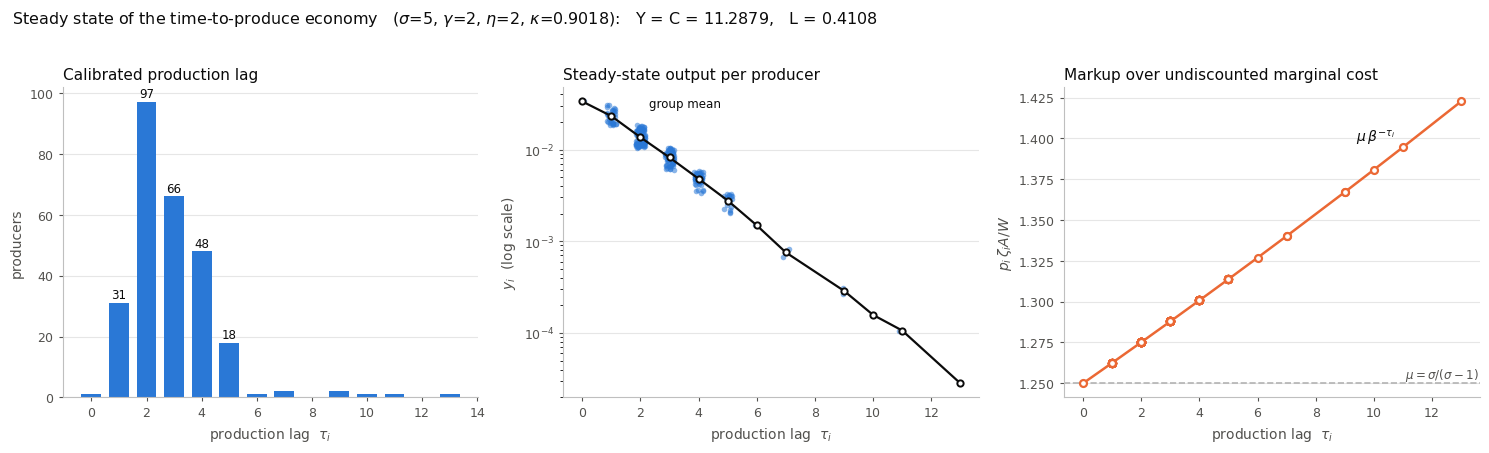

In [10]:
BLUE, ORANGE, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    ax.grid(axis='y', color='0.9', lw=0.8)
    ax.set_axisbelow(True)

t_idx = by_tau.index.to_numpy()

# --- calibrated distribution of the production lag ------------------------------------
ax = axes[0]
ax.bar(t_idx, by_tau['firms'].to_numpy(), width=0.72, color=BLUE, linewidth=0)
for t, nfi in zip(t_idx, by_tau['firms'].to_numpy()):
    if nfi >= 15:
        ax.text(t, nfi + 1.5, str(nfi), ha='center', fontsize=8.5, color=INK)
ax.set_xlabel(r'production lag  $\tau_i$', color=MUTED)
ax.set_ylabel('producers', color=MUTED)
ax.set_title('Calibrated production lag', color=INK, fontsize=11, loc='left')

# --- steady-state output per producer -------------------------------------------------
ax = axes[1]
ax.scatter(firms['tau_i'] + np.random.default_rng(0).uniform(-.16, .16, len(firms)),
           firms['y_i'], s=16, color=BLUE, alpha=.55, linewidth=0)
ax.plot(t_idx, by_tau['mean y_i'].to_numpy(), color=INK, lw=1.6, marker='o', ms=4.5,
        markerfacecolor='white', markeredgecolor=INK, markeredgewidth=1.4, zorder=3)
ax.set_yscale('log')
ax.set_xlabel(r'production lag  $\tau_i$', color=MUTED)
ax.set_ylabel(r'$y_i$  (log scale)', color=MUTED)
ax.set_title('Steady-state output per producer', color=INK, fontsize=11, loc='left')
ax.annotate('group mean', xy=(t_idx[2], by_tau['mean y_i'].to_numpy()[2]),
            xytext=(6, 22), textcoords='offset points', fontsize=8.5, color=INK)

# --- the delay as a lag-specific markup -----------------------------------------------
ax = axes[2]
eff_mu = firms['p_i'].to_numpy() / (ss['W'] / firms['zeta_i'].to_numpy())
ax.axhline(mu, color='0.7', lw=1.2, ls='--', zorder=1)
ax.text(13.6, mu, r'  $\mu=\sigma/(\sigma-1)$', va='bottom', ha='right',
        fontsize=8.5, color=MUTED)
ax.plot(firms['tau_i'].to_numpy(), eff_mu, color=ORANGE, lw=1.8, marker='o', ms=5,
        markerfacecolor='white', markeredgecolor=ORANGE, markeredgewidth=1.6, zorder=3)
ax.set_xlabel(r'production lag  $\tau_i$', color=MUTED)
ax.set_ylabel(r'$p_i\,\zeta_i A / W$', color=MUTED)
ax.set_title('Markup over undiscounted marginal cost', color=INK, fontsize=11, loc='left')
ax.annotate(r'$\mu\,\beta^{-\tau_i}$', xy=(11, mu * beta ** -11), xytext=(-34, 4),
            textcoords='offset points', fontsize=10, color=INK)

fig.suptitle(f'Steady state of the time-to-produce economy   '
             rf'($\sigma$={sigma:.0f}, $\gamma$={gamma:.0f}, $\eta$={eta:.0f}, '
             rf'$\kappa$={kappa:.4f}):   Y = C = {ss["Y"]:.4f},   L = {ss["L"]:.4f}',
             fontsize=11.5, color=INK, x=0.011, ha='left', y=1.02)
fig.tight_layout()
fig.savefig('../ss_levels.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 9. How the levels move with the conventions

Real *ratios* ($W/P$, shares, $\Theta/Z$) are the economics; the scale of $Y$ and $\tilde A$
depends on two conventions that the notebooks make silently.

* **CES weights.**  The `P0` formula in the shock notebooks sums over the 269 producers
  without weights, so $\tilde A$ scales with $n$.  Weights $1/n$ give the unit-measure
  reading instead.  Log deviations — all the shock notebooks ever plot — are identical
  either way.
* **$\kappa^{\Delta}$ vs $\kappa$.**  The `Z_PHYS` line in the `new_fixed*` notebooks uses
  $\kappa(\tau+N)$ rather than $\kappa^{\tau}(\tau+N)$; that removes the technological cost
  of waiting and leaves only the discount cost, which raises the level a great deal.
* **$\Delta+1$ discount terms.**  Multiplies every $z_i$ by $\beta$, so it scales
  $\tilde A$, $W/P$ and hence $L$ and $Y$, but leaves relative prices and $\mathcal D$ alone.

In [11]:
variants = {
    'baseline  (code: sum weights, kappa^tau, beta^tau)': dict(),
    'unit measure  (weights = 1/n)':                      dict(weights=np.ones(NFIRMS) / NFIRMS),
    'Delta+1 discount terms  (beta^(tau+1))':             dict(extra_delta=1),
    'Z_PHYS variant  (kappa^1 (tau+N))':                  dict(kappa_power=False),
}
cols = ['Y', 'C', 'L', 'Theta', 'A_til', 'Z_agg', 'D', 'real_wage', 'P']
tab = pd.DataFrame({k: {c: steady_state(**kw)[c] for c in cols} for k, kw in variants.items()}).T
tab['Theta/Z']    = tab['Theta'] / tab['Z_agg']
tab['labour sh.'] = [steady_state(**kw)['W'] * steady_state(**kw)['L'] /
                     (steady_state(**kw)['P'] * steady_state(**kw)['Y']) for kw in variants.values()]
with pd.option_context('display.float_format', '{:,.6g}'.format):
    display(tab)

print('Real wage, labour share, D and Theta/Z are unchanged by the weighting;')
print('only the scale of Y, L, A_til and P moves with it.')

,Y,C,L,Theta,A_til,Z_agg,D,real_wage,P,Theta/Z,labour sh.
"baseline (code: sum weights, kappa^tau, beta^tau)",11.2879,11.2879,0.410776,27.4795,26.875,27.4868,0.978003,21.5,0.0465116,0.999732,0.782402
unit measure (weights = 1/n),3.95399,3.95399,0.582727,6.78532,6.63606,6.78714,0.978003,5.30885,0.188365,0.999732,0.782402
Delta+1 discount terms (beta^(tau+1)),11.2599,11.2599,0.409756,27.4795,26.6089,27.4868,0.96832,21.2871,0.0469767,0.999732,0.774656
Z_PHYS variant (kappa^1 (tau+N)),12.7238,12.7238,0.393922,32.3004,31.4026,32.3188,0.972204,25.1221,0.0398056,0.99943,0.777763


Real wage, labour share, D and Theta/Z are unchanged by the weighting;
only the scale of Y, L, A_til and P moves with it.
